In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

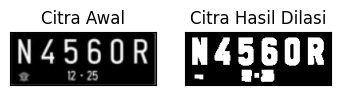

In [4]:
# Dilation without library

def dilasi_citra(F, w):
  #size image
  p,q = F.shape

  imgD = np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED = np.ones((w,w), dtype=np.uint8)
  constant1 = (w-1)//2 # adding '/' 2 times for gettting integer number, not float that can cause error

  #Dilation Process
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/platnomor.jpg',0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()